In [2]:
import pandas as pd

url = "https://zenodo.org/records/11275211/files/India_Flood_Inventory_v3.csv?download=1"

# Load dataset
flood_df = pd.read_csv(url)

# Remove unwanted spaces from all column names
flood_df.columns = flood_df.columns.str.strip()

print("Total flood records:", len(flood_df))

# Extract Mumbai and Mumbai Suburban records
mumbai_floods = flood_df[
    flood_df["Districts"].fillna("").str.contains(
        r"Mumbai|Mumbai Suburban",
        case=False,
        regex=True
    )
].copy()

# Select relevant columns
columns = [
    "UEI",
    "Start Date",
    "End Date",
    "Duration(Days)",
    "Main Cause",
    "Location",
    "Districts",
    "State",
    "Latitude",
    "Longitude",
    "Severity",
    "Area Affected",
    "Human fatality",
    "Human injured",
    "Human Displaced",
    "Description of Casualties/injured",
    "Extent of damage"
]

mumbai_floods = mumbai_floods[columns].copy()

# Save dataset
mumbai_floods.to_csv(
    "mumbai_historical_flood_events.csv",
    index=False
)

print("\nMumbai flood events:", len(mumbai_floods))

display(mumbai_floods)

Total flood records: 6876

Mumbai flood events: 182


,UEI,Start Date,End Date,Duration(Days),Main Cause,Location,Districts,State,Latitude,Longitude,Severity,Area Affected,Human fatality,Human injured,Human Displaced,Description of Casualties/injured,Extent of damage
19,UEI-IMD-FL-1969-0008,15-09-1969 00:00,22-09-1969 00:00,8.0,floods,NaN,"Gondia, Bhandara, Jalgaon, Wardha, Buldhana, A...","Maharashtra, Telangana",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
43,UEI-IMD-FL-1971-0011,22-09-1971 00:00,28-09-1971 00:00,7.0,floods,NaN,"Pashchim Champaran, Purbi Champaran, Sitamarhi...","Bihar, Maharashtra",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
62,UEI-IMD-FL-1973-0007,01-07-1973 00:00,14-07-1973 00:00,14.0,heavy rains,NaN,"Churu, Jhunjhunu, Jaisalmer, Sikar, Alwar, Jai...","Rajasthan, Bihar, Madhya Pradesh, Gujarat, Mah...",NaN,NaN,NaN,NaN,90.0,NaN,NaN,90 persons were reported washed away,"Caused damage in life,property. Crops worth se..."
74,UEI-IMD-FL-1974-0003,01-07-1974 00:00,07-08-1974 00:00,38.0,heavy rains,NaN,Mumbai (Colaba),Maharashtra,NaN,NaN,NaN,NaN,50.0,NaN,NaN,50 lifes were lost,"Recorded,exceptionally heavy rainfall of 58cm ..."
94,UEI-IMD-FL-1975-0018,20-06-1975 00:00,06-09-1975 00:00,79.0,heavy rains,NaN,Mumbai,Maharashtra,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Flooded many low lying areas. Road traffic,tel..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6663,UEI-IMD-FL-2023-0441,28-06-2023 00:00,28-06-2023 00:00,1.0,Heavy Rains & Floods,NaN,Mumbai Suburban,Maharashtra,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN
6666,UEI-IMD-FL-2023-0444,29-06-2023 00:00,29-06-2023 00:00,1.0,Heavy Rains,NaN,Mumbai,Maharashtra,NaN,NaN,NaN,NaN,1.0,5.0,NaN,NaN,NaN
6676,UEI-IMD-FL-2023-0454,19-07-2023 00:00,19-07-2023 00:00,1.0,Heavy Rains & Floods,NaN,Mumbai,Maharashtra,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6682,UEI-IMD-FL-2023-0460,20-07-2023 00:00,20-07-2023 00:00,1.0,Heavy Rains & Floods,NaN,Mumbai,Maharashtra,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# inspect the Mumbai records

In [3]:
# Split district names into individual entries
mumbai_floods["district_list"] = (
    mumbai_floods["Districts"]
    .fillna("")
    .apply(lambda x: [d.strip() for d in x.split(",")])
)

# Identify exact Mumbai district matches
MUMBAI_NAMES = [
    "Mumbai",
    "Mumbai Suburban",
    "Mumbai (Colaba)"
]

mumbai_floods["matched_mumbai_districts"] = (
    mumbai_floods["district_list"]
    .apply(
        lambda districts: [
            d for d in districts
            if d in MUMBAI_NAMES
        ]
    )
)

# Count records
print("Total extracted records:", len(mumbai_floods))

print(
    "Records mentioning Mumbai:",
    mumbai_floods["matched_mumbai_districts"].apply(
        lambda x: len(x) > 0
    ).sum()
)

print(
    "Records involving multiple districts:",
    mumbai_floods["district_list"].apply(
        lambda x: len(x) > 1
    ).sum()
)

# Display unique Mumbai-related district names
print("\nMumbai-related district entries:")

display(
    mumbai_floods[
        mumbai_floods["matched_mumbai_districts"].apply(
            lambda x: len(x) > 0
        )
    ][
        ["UEI", "Start Date", "End Date", "Districts",
         "Main Cause", "Severity"]
    ].head(30)
)

Total extracted records: 182
Records mentioning Mumbai: 182
Records involving multiple districts: 80

Mumbai-related district entries:


,UEI,Start Date,End Date,Districts,Main Cause,Severity
19,UEI-IMD-FL-1969-0008,15-09-1969 00:00,22-09-1969 00:00,"Gondia, Bhandara, Jalgaon, Wardha, Buldhana, A...",floods,NaN
43,UEI-IMD-FL-1971-0011,22-09-1971 00:00,28-09-1971 00:00,"Pashchim Champaran, Purbi Champaran, Sitamarhi...",floods,NaN
62,UEI-IMD-FL-1973-0007,01-07-1973 00:00,14-07-1973 00:00,"Churu, Jhunjhunu, Jaisalmer, Sikar, Alwar, Jai...",heavy rains,NaN
74,UEI-IMD-FL-1974-0003,01-07-1974 00:00,07-08-1974 00:00,Mumbai (Colaba),heavy rains,NaN
94,UEI-IMD-FL-1975-0018,20-06-1975 00:00,06-09-1975 00:00,Mumbai,heavy rains,NaN
174,UEI-IMD-FL-1978-0042,08-06-1978 00:00,14-06-1978 00:00,"Beed, Mumbai","moderate to severe, moderate",NaN
176,UEI-IMD-FL-1978-0044,08-07-1978 00:00,14-07-1978 00:00,Mumbai,moderate,NaN
232,UEI-IMD-FL-1979-0033,24-06-1979 00:00,24-06-1979 00:00,Mumbai,flash floods,NaN
291,UEI-IMD-FL-1980-0031,15-06-1980 00:00,15-06-1980 00:00,Mumbai,heavy rains,NaN
292,UEI-IMD-FL-1980-0032,01-07-1980 00:00,07-07-1980 00:00,Mumbai,heavy rains,NaN


# separate the two categories

In [4]:
# Normalize district names
mumbai_floods["district_list"] = (
    mumbai_floods["Districts"]
    .fillna("")
    .apply(lambda x: [d.strip() for d in x.split(",") if d.strip()])
)

# Accepted Mumbai-region district names
MUMBAI_NAMES = {
    "Mumbai",
    "Mumbai Suburban",
    "Mumbai (Colaba)"
}

# Check whether all listed districts belong to Mumbai
mumbai_floods["mumbai_only"] = (
    mumbai_floods["district_list"]
    .apply(
        lambda districts: (
            len(districts) > 0
            and all(d in MUMBAI_NAMES for d in districts)
        )
    )
)

# Separate records
mumbai_only_events = mumbai_floods[
    mumbai_floods["mumbai_only"]
].copy()

multi_district_events = mumbai_floods[
    ~mumbai_floods["mumbai_only"]
].copy()

print("Total Mumbai-related events:", len(mumbai_floods))
print("Mumbai-only events:", len(mumbai_only_events))
print("Multi-district events:", len(multi_district_events))

print("\nMumbai-only events:")
display(
    mumbai_only_events[
        ["UEI", "Start Date", "End Date", "Districts", "Main Cause"]
    ].head(20)
)

print("\nMulti-district events:")
display(
    multi_district_events[
        ["UEI", "Start Date", "End Date", "Districts", "Main Cause"]
    ].head(10)
)

Total Mumbai-related events: 182
Mumbai-only events: 104
Multi-district events: 78

Mumbai-only events:


,UEI,Start Date,End Date,Districts,Main Cause
74,UEI-IMD-FL-1974-0003,01-07-1974 00:00,07-08-1974 00:00,Mumbai (Colaba),heavy rains
94,UEI-IMD-FL-1975-0018,20-06-1975 00:00,06-09-1975 00:00,Mumbai,heavy rains
176,UEI-IMD-FL-1978-0044,08-07-1978 00:00,14-07-1978 00:00,Mumbai,moderate
232,UEI-IMD-FL-1979-0033,24-06-1979 00:00,24-06-1979 00:00,Mumbai,flash floods
291,UEI-IMD-FL-1980-0031,15-06-1980 00:00,15-06-1980 00:00,Mumbai,heavy rains
292,UEI-IMD-FL-1980-0032,01-07-1980 00:00,07-07-1980 00:00,Mumbai,heavy rains
293,UEI-IMD-FL-1980-0033,04-08-1980 00:00,04-08-1980 00:00,Mumbai,heavy rains
294,UEI-IMD-FL-1980-0034,21-08-1980 00:00,22-08-1980 00:00,Mumbai,heavy rains
366,UEI-IMD-FL-1981-0046,22-06-1981 00:00,28-06-1981 00:00,Mumbai,heavy rains
373,UEI-IMD-FL-1981-0053,22-08-1981 00:00,28-08-1981 00:00,Mumbai,heavy rains



Multi-district events:


,UEI,Start Date,End Date,Districts,Main Cause
19,UEI-IMD-FL-1969-0008,15-09-1969 00:00,22-09-1969 00:00,"Gondia, Bhandara, Jalgaon, Wardha, Buldhana, A...",floods
43,UEI-IMD-FL-1971-0011,22-09-1971 00:00,28-09-1971 00:00,"Pashchim Champaran, Purbi Champaran, Sitamarhi...",floods
62,UEI-IMD-FL-1973-0007,01-07-1973 00:00,14-07-1973 00:00,"Churu, Jhunjhunu, Jaisalmer, Sikar, Alwar, Jai...",heavy rains
174,UEI-IMD-FL-1978-0042,08-06-1978 00:00,14-06-1978 00:00,"Beed, Mumbai","moderate to severe, moderate"
638,UEI-IMD-FL-1984-0058,30-06-1984 00:00,02-07-1984 00:00,"Amravati, Mumbai, Kolhapur, Mumbai, Mumbai Sub...","heavy rains, moderate, severe"
643,UEI-IMD-FL-1984-0063,17-07-1984 00:00,19-07-1984 00:00,"Mumbai, Mumbai Suburban, Raigad, Ratnagiri, Si...",severe
731,UEI-IMD-FL-1985-0044,16-06-1985 00:00,16-06-1985 00:00,"Mumbai, Jalgaon, Ratnagiri, Thane","heavy rains, flash flood"
817,UEI-IMD-FL-1986-0056,28-06-1986 00:00,28-06-1986 00:00,"Mumbai,Thane",heavy rains
822,UEI-IMD-FL-1986-0061,07-08-1986 00:00,07-08-1986 00:00,"Mumbai, Ratnagiri, Sindhudurg,Thane","heavy rains, severe"
943,UEI-IMD-FL-1988-0053,14-06-1988 00:00,14-06-1988 00:00,"Mumbai, Nashik",heavy rains


# clean the 104 Mumbai-only records

In [5]:
# Work on a separate copy
clean_floods = mumbai_only_events.copy()

# Convert dates into datetime format
clean_floods["Start Date"] = pd.to_datetime(
    clean_floods["Start Date"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

clean_floods["End Date"] = pd.to_datetime(
    clean_floods["End Date"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

# Remove records with invalid dates
clean_floods = clean_floods.dropna(
    subset=["Start Date", "End Date"]
).copy()

# Calculate actual event duration
clean_floods["calculated_duration_days"] = (
    (clean_floods["End Date"] - clean_floods["Start Date"]).dt.days + 1
)

# Extract year and month
clean_floods["year"] = clean_floods["Start Date"].dt.year
clean_floods["month"] = clean_floods["Start Date"].dt.month

# Check duplicate event IDs
print("Records after date cleaning:", len(clean_floods))
print("Duplicate UEI records:", clean_floods["UEI"].duplicated().sum())

print("\nDate range:")
print("First event:", clean_floods["Start Date"].min())
print("Last event:", clean_floods["Start Date"].max())

print("\nMissing values:")
display(clean_floods.isnull().sum().to_frame("Missing values"))

print("\nEvent duration comparison:")
display(
    clean_floods[
        ["UEI", "Duration(Days)", "calculated_duration_days"]
    ].head(15)
)

# Save cleaned data
clean_floods.to_csv(
    "mumbai_historical_flood_events_cleaned.csv",
    index=False
)

display(clean_floods.head(20))

Records after date cleaning: 104
Duplicate UEI records: 0

Date range:
First event: 1974-07-01 00:00:00
Last event: 2023-07-20 00:00:00

Missing values:


,Missing values
UEI,0
Start Date,0
End Date,0
Duration(Days),0
Main Cause,0
Location,104
Districts,0
State,0
Latitude,104
Longitude,104



Event duration comparison:


,UEI,Duration(Days),calculated_duration_days
74,UEI-IMD-FL-1974-0003,38.0,38
94,UEI-IMD-FL-1975-0018,79.0,79
176,UEI-IMD-FL-1978-0044,7.0,7
232,UEI-IMD-FL-1979-0033,1.0,1
291,UEI-IMD-FL-1980-0031,1.0,1
292,UEI-IMD-FL-1980-0032,7.0,7
293,UEI-IMD-FL-1980-0033,1.0,1
294,UEI-IMD-FL-1980-0034,2.0,2
366,UEI-IMD-FL-1981-0046,7.0,7
373,UEI-IMD-FL-1981-0053,7.0,7


,UEI,Start Date,End Date,Duration(Days),Main Cause,Location,Districts,State,Latitude,Longitude,...,Human injured,Human Displaced,Description of Casualties/injured,Extent of damage,district_list,matched_mumbai_districts,mumbai_only,calculated_duration_days,year,month
74,UEI-IMD-FL-1974-0003,1974-07-01,1974-08-07,38.0,heavy rains,NaN,Mumbai (Colaba),Maharashtra,NaN,NaN,...,NaN,NaN,50 lifes were lost,"Recorded,exceptionally heavy rainfall of 58cm ...",[Mumbai (Colaba)],[Mumbai (Colaba)],True,38,1974,7
94,UEI-IMD-FL-1975-0018,1975-06-20,1975-09-06,79.0,heavy rains,NaN,Mumbai,Maharashtra,NaN,NaN,...,NaN,NaN,NaN,"Flooded many low lying areas. Road traffic,tel...",[Mumbai],[Mumbai],True,79,1975,6
176,UEI-IMD-FL-1978-0044,1978-07-08,1978-07-14,7.0,moderate,NaN,Mumbai,Maharashtra,NaN,NaN,...,NaN,NaN,1 child killed in a landslide,Road traffic dislocated,[Mumbai],[Mumbai],True,7,1978,7
232,UEI-IMD-FL-1979-0033,1979-06-24,1979-06-24,1.0,flash floods,NaN,Mumbai,Maharashtra,NaN,NaN,...,NaN,NaN,2 children died in house collapse,i)Several areas flooded ii)train services/tele...,[Mumbai],[Mumbai],True,1,1979,6
291,UEI-IMD-FL-1980-0031,1980-06-15,1980-06-15,1.0,heavy rains,NaN,Mumbai,Maharashtra,NaN,NaN,...,2.0,NaN,"1 girl died,2 persons injured in wall collapse","i)City life paralysed ii)Rail tracks,low lying...",[Mumbai],[Mumbai],True,1,1980,6
292,UEI-IMD-FL-1980-0032,1980-07-01,1980-07-07,7.0,heavy rains,NaN,Mumbai,Maharashtra,NaN,NaN,...,5.0,NaN,"2 persons died,5 injured in houses collapse",i)Low lying areas flooded ii)Vehicular traffic...,[Mumbai],[Mumbai],True,7,1980,7
293,UEI-IMD-FL-1980-0033,1980-08-04,1980-08-04,1.0,heavy rains,NaN,Mumbai,Maharashtra,NaN,NaN,...,NaN,NaN,"1 woman,and a cow died on the spot due to elec...",i)Low lying areas flooded ii)Rail tracks subme...,[Mumbai],[Mumbai],True,1,1980,8
294,UEI-IMD-FL-1980-0034,1980-08-21,1980-08-22,2.0,heavy rains,NaN,Mumbai,Maharashtra,NaN,NaN,...,NaN,NaN,45 persons lost their lives due to drowning/ho...,"i)The tiny streams of Dahisar,Paoisor inundate...",[Mumbai],[Mumbai],True,2,1980,8
366,UEI-IMD-FL-1981-0046,1981-06-22,1981-06-28,7.0,heavy rains,NaN,Mumbai,Maharashtra,NaN,NaN,...,NaN,NaN,NaN,(i)City transport system thrown out of gear (i...,[Mumbai],[Mumbai],True,7,1981,6
373,UEI-IMD-FL-1981-0053,1981-08-22,1981-08-28,7.0,heavy rains,NaN,Mumbai,Maharashtra,NaN,NaN,...,NaN,NaN,12 persons died,7 building collapsed,[Mumbai],[Mumbai],True,7,1981,8


# Check whether the descriptions identify individual localities

In [6]:
# Check whether locality names appear in historical flood descriptions

localities = [
    "Bandra",
    "Santacruz",
    "Vile Parle",
    "Andheri",
    "Jogeshwari",
    "Goregaon",
    "Malad",
    "Kandivali",
    "Borivali"
]

text_columns = [
    "Description of Casualties/injured",
    "Extent of damage"
]

# Combine available descriptive text
clean_floods["combined_description"] = (
    clean_floods[text_columns]
    .fillna("")
    .agg(" ".join, axis=1)
)

# Find locality mentions
locality_matches = []

for _, row in clean_floods.iterrows():
    description = row["combined_description"]

    for locality in localities:
        if locality.lower() in description.lower():
            locality_matches.append({
                "UEI": row["UEI"],
                "Start Date": row["Start Date"],
                "Locality": locality,
                "Description": description
            })

locality_audit = pd.DataFrame(locality_matches)

print("Total locality mentions:", len(locality_audit))
print(
    "Unique flood events mentioning localities:",
    locality_audit["UEI"].nunique()
    if not locality_audit.empty else 0
)

display(locality_audit)

Total locality mentions: 6
Unique flood events mentioning localities: 5


,UEI,Start Date,Locality,Description
0,UEI-IMD-FL-1992-0044,1992-08-16,Malad,3 persons of a family including a girl drowned...
1,UEI-IMD-FL-2003-0066,2003-07-07,Borivali,1 youth drowned in falls in Sanjay Gandhi Nati...
2,UEI-IMD-FL-2014-0060,2014-07-13,Malad,"One person died due to roof fell in Colaba, 3 ..."
3,UEI-IMD-FL-2015-0070,2015-07-28,Santacruz,4 persons died at Vakola Santacruz
4,UEI-IMD-FL-2018-0054,2018-03-07,Bandra,One youth washed away from Bandra & 5 others i...
5,UEI-IMD-FL-2018-0054,2018-03-07,Andheri,One youth washed away from Bandra & 5 others i...


# Inspect the complete descriptions of these five events

In [8]:
matched_ueis = locality_audit["UEI"].unique()

event_details = clean_floods[
    clean_floods["UEI"].isin(matched_ueis)
][[
    "UEI",
    "Start Date",
    "End Date",
    "Main Cause",
    "Location",
    "Districts",
    "Description of Casualties/injured",
    "Extent of damage"
]].copy()

pd.set_option("display.max_colwidth", None)

display(event_details.sort_values("Start Date"))

,UEI,Start Date,End Date,Main Cause,Location,Districts,Description of Casualties/injured,Extent of damage
1327,UEI-IMD-FL-1992-0044,1992-08-16,1992-08-16,heavy rains,NaN,Mumbai,3 persons of a family including a girl drowned at Aksa bridge near Malad,NaN
2608,UEI-IMD-FL-2003-0066,2003-07-07,2003-07-07,heavy rains,NaN,Mumbai,"1 youth drowned in falls in Sanjay Gandhi National Park at Borivali,another injured due to wall collapse at Bhandup",(i) Low lying areas inundated (ii)Around 50 trees uprooted
3904,UEI-IMD-FL-2014-0060,2014-07-13,2014-07-13,heavy rains,NaN,Mumbai,"One person died due to roof fell in Colaba, 3 others due to wall collapse in Shiwadi,Malad.",NaN
4002,UEI-IMD-FL-2015-0070,2015-07-28,2015-07-28,heavy rains,NaN,Mumbai,4 persons died at Vakola Santacruz,NaN
4351,UEI-IMD-FL-2018-0054,2018-03-07,2018-03-07,Floods & Heavy rains,NaN,Mumbai,One youth washed away from Bandra & 5 others injured due to part of Ghokhale bridge collapsed in Andheri.,i) Damage to Ghokhale bridge reported. ii) Rail & Air services disrupted. Flight cancelled.


# Extract locality-level historical incident records

In [9]:
# Save locality-specific historical incident evidence

locality_audit.to_csv(
    "mumbai_locality_historical_incidents.csv",
    index=False
)

print("Historical locality incident records saved.")
print("Total locality mentions:", len(locality_audit))
print("Unique events:", locality_audit["UEI"].nunique())
print("Localities identified:", locality_audit["Locality"].nunique())

Historical locality incident records saved.
Total locality mentions: 6
Unique events: 5
Localities identified: 5


# Assess historical flood records

In [11]:
import pandas as pd

# Load cleaned Mumbai historical flood events
historical_df = pd.read_csv(
    "mumbai_historical_flood_events_cleaned.csv"
)

# Load supplementary locality-specific incident records
incidents_df = pd.read_csv(
    "mumbai_locality_historical_incidents.csv"
)

print("Historical flood events shape:", historical_df.shape)
print("Locality incident records shape:", incidents_df.shape)

print("\nHistorical flood event columns:")
print(historical_df.columns.tolist())

print("\nHistorical flood events preview:")
display(historical_df.head(10))

print("\nLocality incident records:")
display(incidents_df)

# Ensure year is numeric
historical_df["year"] = pd.to_numeric(
    historical_df["year"],
    errors="coerce"
)

print("\nHistorical event year distribution:")
display(
    historical_df["year"]
    .value_counts()
    .sort_index()
)

Historical flood events shape: (104, 23)
Locality incident records shape: (6, 4)

Historical flood event columns:
['UEI', 'Start Date', 'End Date', 'Duration(Days)', 'Main Cause', 'Location', 'Districts', 'State', 'Latitude', 'Longitude', 'Severity', 'Area Affected', 'Human fatality', 'Human injured', 'Human Displaced', 'Description of Casualties/injured', 'Extent of damage', 'district_list', 'matched_mumbai_districts', 'mumbai_only', 'calculated_duration_days', 'year', 'month']

Historical flood events preview:


,UEI,Start Date,End Date,Duration(Days),Main Cause,Location,Districts,State,Latitude,Longitude,...,Human injured,Human Displaced,Description of Casualties/injured,Extent of damage,district_list,matched_mumbai_districts,mumbai_only,calculated_duration_days,year,month
0,UEI-IMD-FL-1974-0003,1974-07-01,1974-08-07,38.0,heavy rains,NaN,Mumbai (Colaba),Maharashtra,NaN,NaN,...,NaN,NaN,50 lifes were lost,"Recorded,exceptionally heavy rainfall of 58cm in Twenty Four hours on 5th July, which was the highest on record. Low level areas in Mumbai were heavily flooded,city life was completely paralysed. Damage to Railway,public property was estimated at Rs. 6 crores.",['Mumbai (Colaba)'],['Mumbai (Colaba)'],True,38,1974,7
1,UEI-IMD-FL-1975-0018,1975-06-20,1975-09-06,79.0,heavy rains,NaN,Mumbai,Maharashtra,NaN,NaN,...,NaN,NaN,NaN,"Flooded many low lying areas. Road traffic,telecommunicaton network were seriously affected. A number of lives were lost due to house collapses",['Mumbai'],['Mumbai'],True,79,1975,6
2,UEI-IMD-FL-1978-0044,1978-07-08,1978-07-14,7.0,moderate,NaN,Mumbai,Maharashtra,NaN,NaN,...,NaN,NaN,1 child killed in a landslide,Road traffic dislocated,['Mumbai'],['Mumbai'],True,7,1978,7
3,UEI-IMD-FL-1979-0033,1979-06-24,1979-06-24,1.0,flash floods,NaN,Mumbai,Maharashtra,NaN,NaN,...,NaN,NaN,2 children died in house collapse,i)Several areas flooded ii)train services/telephone ervices/road transportation disrupted,['Mumbai'],['Mumbai'],True,1,1979,6
4,UEI-IMD-FL-1980-0031,1980-06-15,1980-06-15,1.0,heavy rains,NaN,Mumbai,Maharashtra,NaN,NaN,...,2.0,NaN,"1 girl died,2 persons injured in wall collapse","i)City life paralysed ii)Rail tracks,low lying areas flooded iii)Transport services disrupted iv)Telephone services went away",['Mumbai'],['Mumbai'],True,1,1980,6
5,UEI-IMD-FL-1980-0032,1980-07-01,1980-07-07,7.0,heavy rains,NaN,Mumbai,Maharashtra,NaN,NaN,...,5.0,NaN,"2 persons died,5 injured in houses collapse","i)Low lying areas flooded ii)Vehicular traffic disrupted iii)Rail track on the Ambernath, Badlapur, section washed away iv)A fishing trawler sank in rough seas narrowly escaped from death",['Mumbai'],['Mumbai'],True,7,1980,7
6,UEI-IMD-FL-1980-0033,1980-08-04,1980-08-04,1.0,heavy rains,NaN,Mumbai,Maharashtra,NaN,NaN,...,NaN,NaN,"1 woman,and a cow died on the spot due to electrocution",i)Low lying areas flooded ii)Rail tracks submerged dislocating train services iii)Vehicular traffic came to a standstill iv)Loading/unloading operations in the docks suspended,['Mumbai'],['Mumbai'],True,1,1980,8
7,UEI-IMD-FL-1980-0034,1980-08-21,1980-08-22,2.0,heavy rains,NaN,Mumbai,Maharashtra,NaN,NaN,...,NaN,NaN,45 persons lost their lives due to drowning/house collapse/electrocution,"i)The tiny streams of Dahisar,Paoisor inundated surrounding residential areas,many slums flooded ii)600 people rescued from trees/roof tops by fire-brigade iii)Suburbanan train services suspended iv)300 huts washed away",['Mumbai'],['Mumbai'],True,2,1980,8
8,UEI-IMD-FL-1981-0046,1981-06-22,1981-06-28,7.0,heavy rains,NaN,Mumbai,Maharashtra,NaN,NaN,...,NaN,NaN,NaN,(i)City transport system thrown out of gear (ii)Telephone sysrtem disrupted (iii)Sub urban rail services disrupted,['Mumbai'],['Mumbai'],True,7,1981,6
9,UEI-IMD-FL-1981-0053,1981-08-22,1981-08-28,7.0,heavy rains,NaN,Mumbai,Maharashtra,NaN,NaN,...,NaN,NaN,12 persons died,7 building collapsed,['Mumbai'],['Mumbai'],True,7,1981,8



Locality incident records:


,UEI,Start Date,Locality,Description
0,UEI-IMD-FL-1992-0044,1992-08-16,Malad,3 persons of a family including a girl drowned at Aksa bridge near Malad
1,UEI-IMD-FL-2003-0066,2003-07-07,Borivali,"1 youth drowned in falls in Sanjay Gandhi National Park at Borivali,another injured due to wall collapse at Bhandup (i) Low lying areas inundated (ii)Around 50 trees uprooted"
2,UEI-IMD-FL-2014-0060,2014-07-13,Malad,"One person died due to roof fell in Colaba, 3 others due to wall collapse in Shiwadi,Malad."
3,UEI-IMD-FL-2015-0070,2015-07-28,Santacruz,4 persons died at Vakola Santacruz
4,UEI-IMD-FL-2018-0054,2018-03-07,Bandra,One youth washed away from Bandra & 5 others injured due to part of Ghokhale bridge collapsed in Andheri. i) Damage to Ghokhale bridge reported. ii) Rail & Air services disrupted. Flight cancelled.
5,UEI-IMD-FL-2018-0054,2018-03-07,Andheri,One youth washed away from Bandra & 5 others injured due to part of Ghokhale bridge collapsed in Andheri. i) Damage to Ghokhale bridge reported. ii) Rail & Air services disrupted. Flight cancelled.



Historical event year distribution:


year
1974    1
1975    1
1978    1
1979    1
1980    4
1981    3
1983    1
1984    4
1985    2
1988    3
1990    4
1991    2
1992    5
1993    4
1994    7
1995    1
1996    4
1997    2
1998    2
2000    2
2001    2
2002    2
2003    3
2004    1
2005    2
2006    1
2009    1
2010    1
2011    1
2012    2
2013    1
2014    2
2015    1
2016    3
2017    1
2018    1
2019    3
2020    2
2021    4
2022    8
2023    8
Name: count, dtype: int64

# Check which historical events overlap with our weather period

In [12]:
# Parse historical event dates
historical_df["Start Date"] = pd.to_datetime(
    historical_df["Start Date"],
    errors="coerce"
)

historical_df["End Date"] = pd.to_datetime(
    historical_df["End Date"],
    errors="coerce"
)

# Define weather dataset period
weather_start = pd.Timestamp("2015-01-01")
weather_end = pd.Timestamp("2025-12-31 23:00:00")

# Check event date validity
invalid_dates = historical_df[
    historical_df["Start Date"].isna()
    | historical_df["End Date"].isna()
    | (historical_df["End Date"] < historical_df["Start Date"])
]

# Select events that overlap the weather period
overlapping_events = historical_df[
    (historical_df["Start Date"] <= weather_end)
    & (historical_df["End Date"] >= weather_start)
].copy()

print("Historical events:", len(historical_df))
print("Events with invalid dates:", len(invalid_dates))
print("Events overlapping weather period:", len(overlapping_events))

print("\nOverlapping events by year:")
display(
    overlapping_events["year"]
    .value_counts()
    .sort_index()
)

print("\nOverlapping event details:")
display(
    overlapping_events[
        ["UEI", "Start Date", "End Date", "Main Cause",
         "Districts", "Severity", "Extent of damage"]
    ].sort_values("Start Date")
)

Historical events: 104
Events with invalid dates: 0
Events overlapping weather period: 31

Overlapping events by year:


year
2015    1
2016    3
2017    1
2018    1
2019    3
2020    2
2021    4
2022    8
2023    8
Name: count, dtype: int64


Overlapping event details:


,UEI,Start Date,End Date,Main Cause,Districts,Severity,Extent of damage
73,UEI-IMD-FL-2015-0070,2015-07-28,2015-07-28,heavy rains,Mumbai,NaN,NaN
74,UEI-IMD-FL-2016-0093,2016-06-20,2016-06-20,heavy rains,Mumbai,NaN,22 trees uprooted causing disruption in vehicular traffic.
75,UEI-IMD-FL-2016-0094,2016-06-25,2016-06-25,heavy rains,Mumbai,NaN,NaN
76,UEI-IMD-FL-2016-0100,2016-07-30,2016-07-31,heavy rains,Mumbai,NaN,i) Damage to Ground-plus-three structure building & security cabin reported ii) A car & an auto-rickshaw damaged as tree fell on it.
77,UEI-IMD-FL-2017-0080,2017-06-26,2017-06-26,Heavy Rains,Mumbai,NaN,i) Damage to houses reported. ii) 48 trees uprooted.
78,UEI-IMD-FL-2018-0054,2018-03-07,2018-03-07,Floods & Heavy rains,Mumbai,NaN,i) Damage to Ghokhale bridge reported. ii) Rail & Air services disrupted. Flight cancelled.
79,UEI-IMD-FL-2019-0096,2019-02-08,2019-02-08,Heavy Rains,Mumbai,NaN,A tree uprooted & fell on a wall in Chandivli.
80,UEI-IMD-FL-2019-0104,2019-05-09,2019-05-09,Heavy Rains & Flood,Mumbai,NaN,"Around 1300 people from Kurla west evacuated with the help of Navy,NDRF personnel."
81,UEI-IMD-FL-2019-0105,2019-06-09,2019-06-09,Heavy Rains & Flood,Mumbai,NaN,NaN
82,UEI-IMD-FL-2020-0077,2020-06-18,2020-06-18,Heavy Rains,Mumbai,NaN,NaN


# inspect locality-specific historical incidents

In [15]:
# Load locality-specific historical incidents
incidents_df = pd.read_csv("mumbai_locality_historical_incidents.csv")

# Clean column names
incidents_df.columns = incidents_df.columns.str.strip().str.lower()

# Parse incident start dates
incidents_df["start date"] = pd.to_datetime(
    incidents_df["start date"],
    errors="coerce"
)

# Extract year from start date
incidents_df["year"] = incidents_df["start date"].dt.year

# Keep incidents within the weather dataset period
incidents_in_period = incidents_df[
    incidents_df["year"].between(2015, 2025)
].copy()

print("Total locality-specific incidents:", len(incidents_df))
print("Incidents within weather period:", len(incidents_in_period))

display(
    incidents_in_period.sort_values("start date")
)

Total locality-specific incidents: 6
Incidents within weather period: 3


,uei,start date,locality,description,year
3,UEI-IMD-FL-2015-0070,2015-07-28,Santacruz,4 persons died at Vakola Santacruz,2015
4,UEI-IMD-FL-2018-0054,2018-03-07,Bandra,One youth washed away from Bandra & 5 others injured due to part of Ghokhale bridge collapsed in Andheri. i) Damage to Ghokhale bridge reported. ii) Rail & Air services disrupted. Flight cancelled.,2018
5,UEI-IMD-FL-2018-0054,2018-03-07,Andheri,One youth washed away from Bandra & 5 others injured due to part of Ghokhale bridge collapsed in Andheri. i) Damage to Ghokhale bridge reported. ii) Rail & Air services disrupted. Flight cancelled.,2018


# check whether the weather data covers these incident dates

In [16]:
# Load the integrated model features
features_df = pd.read_csv(
    "mumbai_flood_model_features.csv",
    usecols=["zone_name", "timestamp"]
)

# Parse timestamps
features_df["timestamp"] = pd.to_datetime(
    features_df["timestamp"],
    errors="coerce"
)

# Get incident dates
incident_dates = incidents_in_period["start date"].dt.date.unique()

# Check weather records available on each incident date
for incident_date in incident_dates:
    date_data = features_df[
        features_df["timestamp"].dt.date == incident_date
    ]

    print(
        incident_date,
        "| Localities with weather data:",
        date_data["zone_name"].nunique(),
        "| Hourly records:",
        len(date_data)
    )

2015-07-28 | Localities with weather data: 9 | Hourly records: 216
2018-03-07 | Localities with weather data: 9 | Hourly records: 216


# save a clean incident reference file

In [17]:
# Keep only the locality-specific incidents within the weather period
historical_reference_df = incidents_in_period[
    ["uei", "start date", "locality", "description"]
].copy()

# Save the cleaned reference file
historical_reference_df.to_csv(
    "mumbai_locality_historical_incidents_in_period.csv",
    index=False
)

print("Saved historical reference file.")
print("Shape:", historical_reference_df.shape)

display(historical_reference_df)

Saved historical reference file.
Shape: (3, 4)


,uei,start date,locality,description
3,UEI-IMD-FL-2015-0070,2015-07-28,Santacruz,4 persons died at Vakola Santacruz
4,UEI-IMD-FL-2018-0054,2018-03-07,Bandra,One youth washed away from Bandra & 5 others injured due to part of Ghokhale bridge collapsed in Andheri. i) Damage to Ghokhale bridge reported. ii) Rail & Air services disrupted. Flight cancelled.
5,UEI-IMD-FL-2018-0054,2018-03-07,Andheri,One youth washed away from Bandra & 5 others injured due to part of Ghokhale bridge collapsed in Andheri. i) Damage to Ghokhale bridge reported. ii) Rail & Air services disrupted. Flight cancelled.


# Check Bhuvan's available historical flood data

In [18]:
import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin

# Bhuvan historical flood portal
URL = "https://bhuvan-app1.nrsc.gov.in/disaster/usrtasks/flood/flood.php?uname=empty"

try:
    response = requests.get(
        URL,
        headers={"User-Agent": "Mozilla/5.0"},
        timeout=30
    )

    print("HTTP Status:", response.status_code)

    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")

    print("\nPage title:", soup.title.get_text(strip=True) if soup.title else "Not found")

    # Find links related to historical flood data
    keywords = [
        "historical",
        "mumbai",
        "maharashtra",
        "inundation",
        "hazard",
        "metadata",
        "webservice",
        "download"
    ]

    matching_links = []

    for link in soup.find_all("a", href=True):
        text = link.get_text(" ", strip=True)
        href = urljoin(URL, link["href"])

        combined_text = (text + " " + href).lower()

        if any(keyword in combined_text for keyword in keywords):
            matching_links.append({
                "link_text": text,
                "url": href
            })

    print("\nRelevant links found:", len(matching_links))

    for item in matching_links:
        print("\nName:", item["link_text"])
        print("URL:", item["url"])

except requests.exceptions.RequestException as e:
    print("Unable to access Bhuvan:", e)

HTTP Status: 200

Page title: Not found

Relevant links found: 6

Name: Bharanipada
URL: https://bhuvan-app1.nrsc.gov.in/disaster/usrtasks/flood/doc/Mumbai_floods_18jul_VAP_tile1.pdf

Name: Tembhi Khodave
URL: https://bhuvan-app1.nrsc.gov.in/disaster/usrtasks/flood/doc/Mumbai_floods_18jul_VAP_tile2.pdf

Name: Virar West
URL: https://bhuvan-app1.nrsc.gov.in/disaster/usrtasks/flood/doc/Mumbai_floods_18jul_VAP_tile3.pdf

Name: Saravali
URL: https://bhuvan-app1.nrsc.gov.in/disaster/usrtasks/flood/doc/Mumbai_floods_18jul_VAP_tile4.pdf

Name: Parts of Maharashtra and Karnataka States
URL: https://bhuvan-app1.nrsc.gov.in/disaster/usrtasks/flood/doc/Maharashtra_floods_28jul_VAP_tile6.pdf

Name: Floods Inundation (8-10 Sept'14)
URL: https://bhuvan-app1.nrsc.gov.in/disaster/usrtasks/flood/vi/JK-SAT3.mp4


# Download and inspect the four PDFs

In [20]:
%pip install pypdf

Note: you may need to restart the kernel to use updated packages.


In [21]:
import requests
import os
from pypdf import PdfReader
from io import BytesIO

# Bhuvan Mumbai flood map PDFs
pdf_urls = {
    "tile1": "https://bhuvan-app1.nrsc.gov.in/disaster/usrtasks/flood/doc/Mumbai_floods_18jul_VAP_tile1.pdf",
    "tile2": "https://bhuvan-app1.nrsc.gov.in/disaster/usrtasks/flood/doc/Mumbai_floods_18jul_VAP_tile2.pdf",
    "tile3": "https://bhuvan-app1.nrsc.gov.in/disaster/usrtasks/flood/doc/Mumbai_floods_18jul_VAP_tile3.pdf",
    "tile4": "https://bhuvan-app1.nrsc.gov.in/disaster/usrtasks/flood/doc/Mumbai_floods_18jul_VAP_tile4.pdf"
}

# Create download folder
os.makedirs("bhuvan_flood_maps", exist_ok=True)

for tile_name, url in pdf_urls.items():

    print("\n" + "=" * 60)
    print("Inspecting:", tile_name)

    try:
        response = requests.get(
            url,
            headers={"User-Agent": "Mozilla/5.0"},
            timeout=60
        )

        response.raise_for_status()

        pdf_path = os.path.join(
            "bhuvan_flood_maps",
            f"{tile_name}.pdf"
        )

        with open(pdf_path, "wb") as file:
            file.write(response.content)

        reader = PdfReader(BytesIO(response.content))

        print("HTTP Status:", response.status_code)
        print("File size:", round(len(response.content) / 1024, 2), "KB")
        print("Pages:", len(reader.pages))
        print("Metadata:", reader.metadata)

        # Extract available PDF text
        for page_number, page in enumerate(reader.pages):
            text = page.extract_text()

            print(f"\nPage {page_number + 1} text:")
            print(text[:3000] if text else "No extractable text")

    except Exception as e:
        print("Error:", e)


Inspecting: tile1
HTTP Status: 200
File size: 399.52 KB
Pages: 1
Metadata: {'/Creator': 'Esri ArcMap 10.7.1.11595', '/CreationDate': 'D:20210719140931+05'}

Page 1 text:
Heavy Rain Affected Areas in Parts of Mumbai & Thane, Maharashtra 
Resourcesat-2 L4FMX  Image of 18-July-2021
For official use
Date of Issue : 19.07.2021
Resoucesat-2 L4FMx of 12-April-2019
nrsc
RRES
National Remote Sensing Centre, ISRO 
Dept. of Space, Govt. of India
Hyderabad- 500 037
E-Mail: flood@nrsc.gov.in
www.nrsc.gov.in
MAP ID: 2021/01
DISASTER EVENT ID: 08-FL-2021-MH
¯ ¯
Location Map
VADA
SHAHAPUR
DAHANU
MURBAD
JAWHAR
VASAI
PALGHAR
BHIWANDI
THANE
KALYAN
MOKHADA M AHAL
ULHASNAGAR
TALASRI
KURLA
BO RIVALI
ANDHERI
BO MBAY CITY
Mumbai-Thane
PALGHAR
Maharashtra State
Pre Flood During Flood
Bharanipada
Water Logging
<--- Kelwa Road <--- Kelwa RoadBharanipada
Sanjeevani Mithaghar Sanjeevani Mithaghar

Inspecting: tile2
HTTP Status: 200
File size: 399.25 KB
Pages: 1
Metadata: {'/Creator': 'Esri ArcMap 10.7.1.11595', '

# inspect the actual map images

In [24]:
%pip install pymupdf

   ---------------------------------------- 0.0/63.0 MB ? eta -:--:--
    --------------------------------------- 1.3/63.0 MB 6.7 MB/s eta 0:00:10
   - -------------------------------------- 2.6/63.0 MB 7.0 MB/s eta 0:00:09
   -- ------------------------------------- 4.2/63.0 MB 6.7 MB/s eta 0:00:09
   --- ------------------------------------ 5.5/63.0 MB 6.6 MB/s eta 0:00:09
   ---- ----------------------------------- 6.6/63.0 MB 6.4 MB/s eta 0:00:09
   ---- ----------------------------------- 7.3/63.0 MB 5.8 MB/s eta 0:00:10
   ----- ---------------------------------- 8.4/63.0 MB 5.7 MB/s eta 0:00:10
   ----- ---------------------------------- 9.4/63.0 MB 5.7 MB/s eta 0:00:10
   ------ --------------------------------- 11.0/63.0 MB 5.7 MB/s eta 0:00:10
   ------- -------------------------------- 12.3/63.0 MB 5.9 MB/s eta 0:00:09
   -------- ------------------------------- 13.6/63.0 MB 5.9 MB/s eta 0:00:09
   --------- ------------------------------ 15.2/63.0 MB 6.0 MB/s eta 0:00:08
  


tile1.pdf


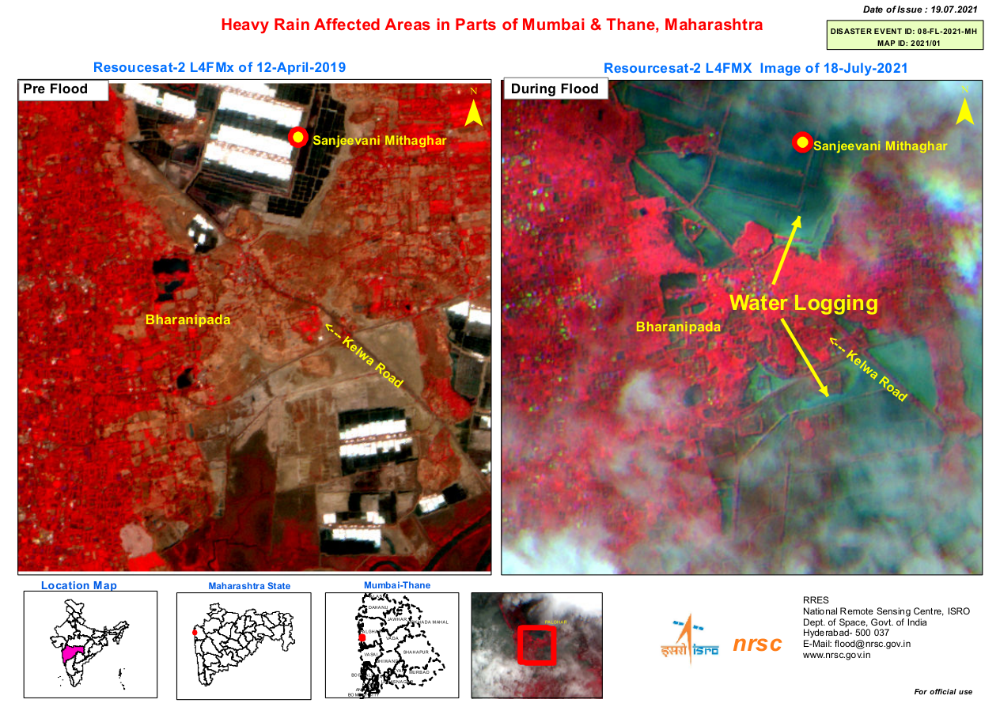


tile2.pdf


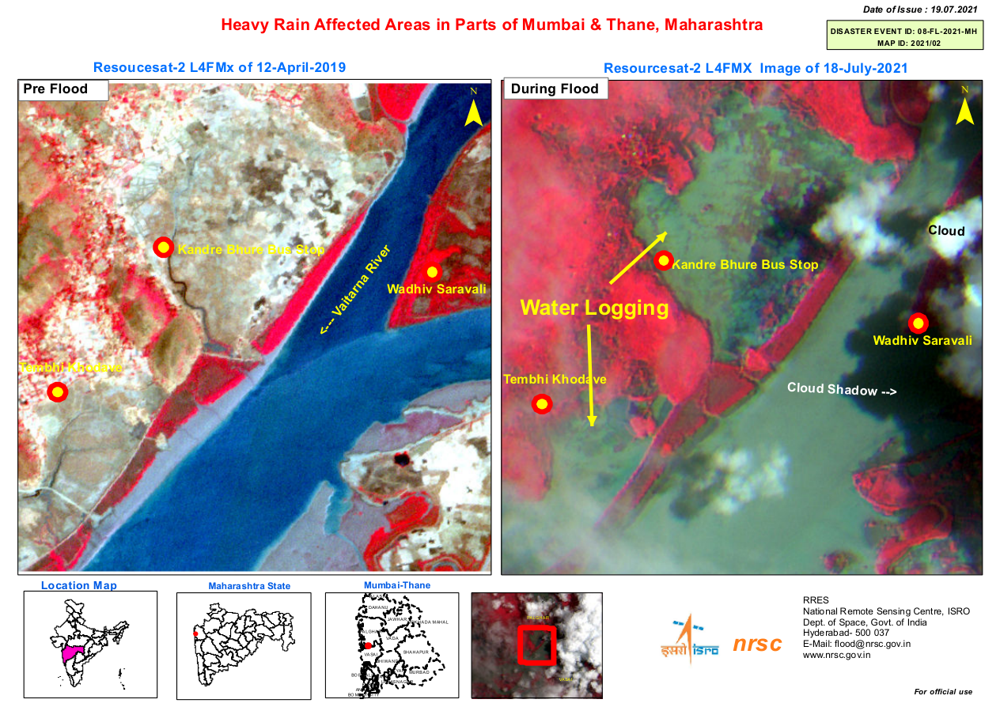


tile3.pdf


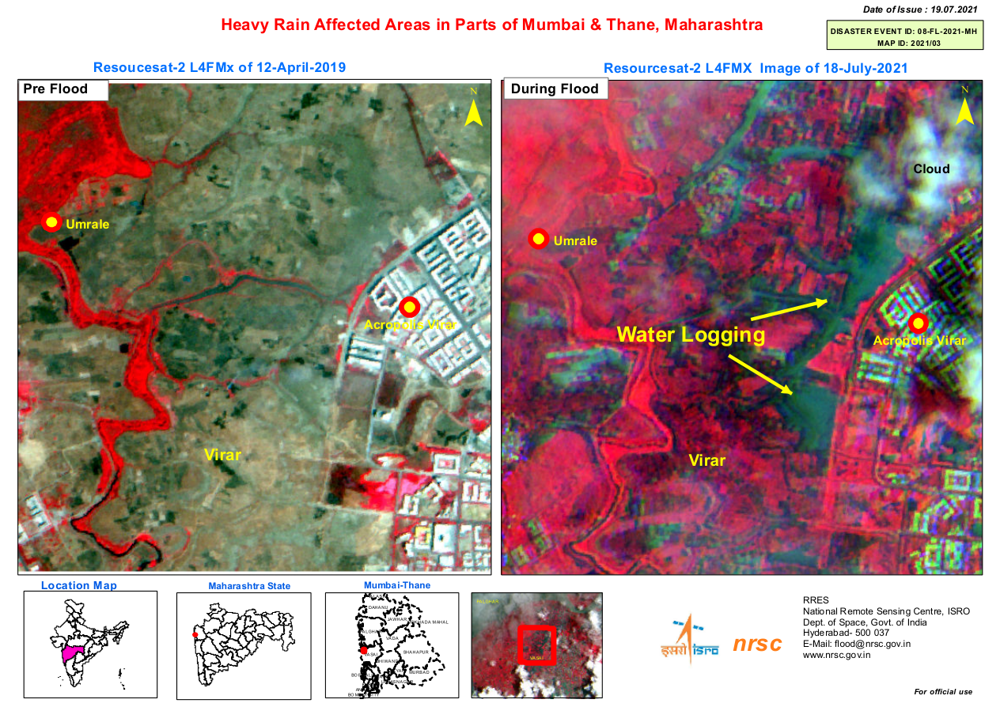


tile4.pdf


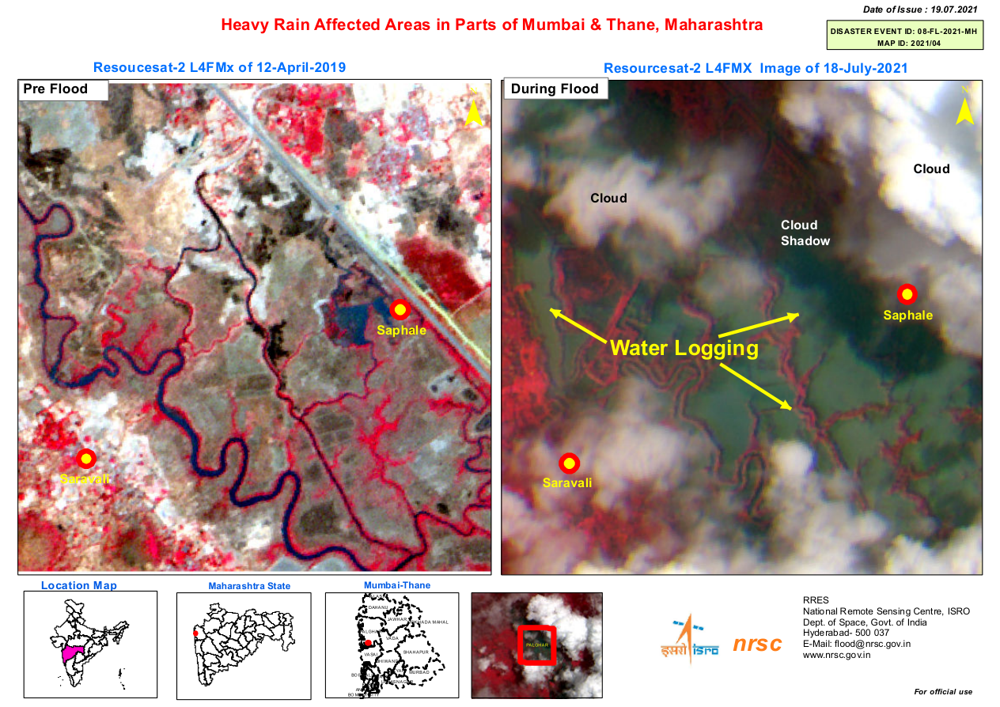

In [26]:
import pymupdf
import os
from IPython.display import display, Image

pdf_folder = "bhuvan_flood_maps"

for filename in sorted(os.listdir(pdf_folder)):
    if filename.lower().endswith(".pdf"):
        pdf_path = os.path.join(pdf_folder, filename)

        doc = fitz.open(pdf_path)
        page = doc[0]

        pix = page.get_pixmap(matrix=fitz.Matrix(1.5, 1.5))
        image_path = os.path.join(
            pdf_folder, filename.replace(".pdf", ".png")
        )
        pix.save(image_path)

        print(f"\n{filename}")
        display(Image(filename=image_path))

# Extract the Mumbai map's actual download/service link

In [27]:
import requests
from bs4 import BeautifulSoup

url = "https://bhuvan-app1.nrsc.gov.in/disaster/usrtasks/flood/flood.php?uname=empty"

response = requests.get(
    url,
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=30
)

soup = BeautifulSoup(response.text, "html.parser")

target = soup.find(
    string=lambda text: text and "Vulnerable Areas : Mumbai Floods" in text
)

if target:
    parent = target.parent

    print("MUMBAI FLOOD VULNERABILITY MAP HTML:\n")

    print(parent.parent.prettify()[:12000])

else:
    print("Mumbai map section not found.")

MUMBAI FLOOD VULNERABILITY MAP HTML:

<p class="heading" id="t1002">
 <img align="left" id="expandt1001" src="../../img/sliderDec.png" style="margin-top:2px" valign="center"/>
 <b>
  Vulnerable Areas : Mumbai Floods
 </b>
</p>



In [28]:
# Inspect the complete Mumbai Floods section

heading = soup.find(id="t1002")

print("SURROUNDING HTML:\n")

if heading:
    section = heading.parent.parent.parent
    print(section.prettify()[:20000])

print("\n\nJAVASCRIPT REFERENCES TO MUMBAI MAP:\n")

for script in soup.find_all("script"):
    script_text = script.string or script.get_text()

    if any(word in script_text.lower() for word in
           ["t1002", "t1001", "mumbai", "flood"]):
        print(script_text[:10000])
        print("-" * 80)

print("\n\nSCRIPT FILES:\n")

for script in soup.find_all("script", src=True):
    print(script["src"])

SURROUNDING HTML:

<html>
 <head>
  <meta content="text/html; charset=utf-8" http-equiv="Content-Type"/>
  <style>
   .layer1 {
margin: 0;
padding: 0;
width: 250px;
}	
.heading {
margin: 1px;
padding: 3px 6px;
cursor: pointer;
position: relative;
color:white;
background-color:#6495ED;
}
.content {
padding: 5px 10px;
background-color:#EBF1F5;
}
p { padding: 0px 0; }
  </style>
  <link href="../../theme/default/style.css" rel="stylesheet" type="text/css"/>
  <link href="../../theme/default/jquery-ui-1.7.2.custom.css" rel="stylesheet" type="text/css"/>
  <body onload="init()" onunload="uninit()" style="margin:0px" width="100%">
   <div class="layer1">
    <p class="heading" id="t1">
     <img align="left" id="expandt1" src="../../img/sliderDec.png" style="margin-top:2px" valign="center"/>
     <b>
      Recent Floods
     </b>
    </p>
    <div class="content">
     <span class="s10b">
      <b>
       Event1
      </b>
      <select id="rf" onchange="displayrecent2(this.value)">
       <

# extract only the Mumbai section

In [29]:
from urllib.parse import urljoin

heading = soup.find("p", id="t1002")

if heading:
    content = heading.find_next_sibling("div", class_="content")

    if content:
        print("MUMBAI FLOOD SECTION:\n")
        print(content.prettify()[:20000])
    else:
        print("Mumbai content div not found.")
else:
    print("Mumbai heading not found.")

print("\nJAVASCRIPT FILE URLS:\n")

for script in soup.find_all("script", src=True):
    script_url = urljoin(URL, script["src"])
    print(script_url)

MUMBAI FLOOD SECTION:

<div class="content">
 <input onclick='if(this.checked) {parent.loadmap("llmumbai","https://bhuvan-ras2.nrsc.gov.in/cgi-bin/mapserv.exe?map=/ms4w/apps/mapfiles/disaster_hyd.map","low_lying_mumbai_12072018_v1")} else { parent.removelayer("llmumbai")}' type="checkbox"/>
 Low Lying Vulnerable Areas
 <img onclick="parent.map.setCenter(new parent.OpenLayers.LonLat(72.9,19.1), 5);" src="img/zoomto.png" style="cursor:pointer" title="Click here to zoom"/>
 <!--div id="llhyd" style="display:none">
	<img width="225px" src='img/hydlg.png'/>
	</div-->
 <p style="text-align:justify; font-family: Arial; font-size: 12px; color: red">
  <b>
   Disclaimer:
  </b>
  <br/>
  Due to limitation in DEM (10m resolution), the areas around Colaba could not be mapped.
  <b>
   It is an experimental product.
  </b>
 </p>
</div>


JAVASCRIPT FILE URLS:

https://bhuvan-app1.nrsc.gov.in/disaster/lib/jquerynew.js
https://bhuvan-app1.nrsc.gov.in/disaster/usrtasks/flood/js/v16.js


# check the WMS service

In [30]:
import requests
import xml.etree.ElementTree as ET

MAP_URL = (
    "https://bhuvan-ras2.nrsc.gov.in/cgi-bin/mapserv.exe"
    "?map=/ms4w/apps/mapfiles/disaster_hyd.map"
)

params = {
    "SERVICE": "WMS",
    "VERSION": "1.1.1",
    "REQUEST": "GetCapabilities"
}

response = requests.get(
    MAP_URL,
    params=params,
    timeout=60
)

print("HTTP Status:", response.status_code)
print("Response type:", response.headers.get("Content-Type"))

if response.status_code == 200:
    root = ET.fromstring(response.content)

    print("\nAVAILABLE MAP LAYERS:\n")

    for layer in root.iter():
        if layer.tag.endswith("Layer"):
            name = layer.find(
                "{http://www.opengis.net/wms}Name"
            )
            title = layer.find(
                "{http://www.opengis.net/wms}Title"
            )

            if name is not None:
                print(
                    "Name:", name.text,
                    "| Title:", title.text if title is not None else ""
                )
else:
    print(response.text[:2000])
    

HTTP Status: 200
Response type: application/vnd.ogc.wms_xml; charset=UTF-8

AVAILABLE MAP LAYERS:



In [31]:
print(response.text[:5000])

<?xml version='1.0' encoding="UTF-8" standalone="no" ?>
<!DOCTYPE WMT_MS_Capabilities SYSTEM "http://schemas.opengis.net/wms/1.1.1/WMS_MS_Capabilities.dtd"
 [
 <!ELEMENT VendorSpecificCapabilities EMPTY>
 ]>  <!-- end of DOCTYPE declaration -->

<WMT_MS_Capabilities version="1.1.1">

<!-- MapServer version 7.0.7 (MS4W 3.2.8) OUTPUT=PNG OUTPUT=JPEG OUTPUT=KML SUPPORTS=PROJ SUPPORTS=AGG SUPPORTS=FREETYPE SUPPORTS=CAIRO SUPPORTS=SVG_SYMBOLS SUPPORTS=SVGCAIRO SUPPORTS=ICONV SUPPORTS=FRIBIDI SUPPORTS=WMS_SERVER SUPPORTS=WMS_CLIENT SUPPORTS=WFS_SERVER SUPPORTS=WFS_CLIENT SUPPORTS=WCS_SERVER SUPPORTS=SOS_SERVER SUPPORTS=FASTCGI SUPPORTS=THREADS SUPPORTS=GEOS SUPPORTS=POINT_Z_M INPUT=JPEG INPUT=POSTGIS INPUT=OGR INPUT=GDAL INPUT=SHAPEFILE -->

<Service>
  <Name>OGC:WMS</Name>
  <Title>disaster_hyd</Title>
  <Abstract>Bhuvan OGC Web Service of Disaster Datasets-Flood</Abstract>
  <KeywordList>
      <Keyword>Disaster</Keyword>
      <Keyword>Flood</Keyword>
      <Keyword>Bhuvan</Keyword>
     

# Extract the layer names

In [32]:
import xml.etree.ElementTree as ET

root = ET.fromstring(response.content)

print("AVAILABLE MAP LAYERS:\n")

for layer in root.iter("Layer"):
    name = layer.find("Name")
    title = layer.find("Title")

    if name is not None:
        print(
            "Layer:", name.text,
            "| Title:", title.text if title is not None else ""
        )

AVAILABLE MAP LAYERS:

Layer: disaster_hyd | Title: disaster_hyd
Layer: low_lying_bengaluru_09092022 | Title: Bhuvan
Layer: low_lying_hyd_23092016_v2 | Title: Bhuvan
Layer: low_lying_chennai_13122016_v1 | Title: Bhuvan
Layer: low_lying_mumbai_12072018_v1 | Title: Bhuvan
Layer: low_lying_area_gaja | Title: Bhuvan
Layer: aggregate_flood_kerala_2018 | Title: Bhuvan
Layer: RS2aibp | Title: Bhuvan


# Check whether we can download actual geographical features

In [33]:
wfs_params = {
    "SERVICE": "WFS",
    "VERSION": "1.1.0",
    "REQUEST": "GetCapabilities"
}

wfs_response = requests.get(
    MAP_URL,
    params=wfs_params,
    timeout=60
)

print("HTTP Status:", wfs_response.status_code)
print("Response type:", wfs_response.headers.get("Content-Type"))

if wfs_response.status_code == 200:
    root_wfs = ET.fromstring(wfs_response.content)

    print("\nAVAILABLE WFS FEATURE TYPES:\n")

    for feature in root_wfs.iter():
        if feature.tag.endswith("FeatureType"):
            name = next(
                (child.text for child in feature
                 if child.tag.endswith("Name")),
                None
            )
            title = next(
                (child.text for child in feature
                 if child.tag.endswith("Title")),
                ""
            )

            if name:
                print("Name:", name, "| Title:", title)
else:
    print(wfs_response.text[:2000])

HTTP Status: 200
Response type: text/xml; charset=UTF-8

AVAILABLE WFS FEATURE TYPES:



In [34]:
print(wfs_response.text[:4000])

<?xml version="1.0" encoding="UTF-8"?>
<ows:ExceptionReport xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance" xmlns:ows="http://www.opengis.net/ows" version="1.1.0" language="en-US" xsi:schemaLocation="http://www.opengis.net/ows http://schemas.opengis.net/ows/1.0.0/owsExceptionReport.xsd">
  <ows:Exception exceptionCode="InvalidParameterValue" locator="request">
    <ows:ExceptionText>msWFSDispatch(): WFS server error. WFS request not enabled. Check wfs/ows_enable_request settings.</ows:ExceptionText>
  </ows:Exception>
</ows:ExceptionReport>



# test GetFeatureInfo for the Mumbai low-lying layer.

In [35]:
import requests

params = {
    "SERVICE": "WMS",
    "VERSION": "1.1.1",
    "REQUEST": "GetFeatureInfo",
    "LAYERS": "low_lying_mumbai_12072018_v1",
    "QUERY_LAYERS": "low_lying_mumbai_12072018_v1",
    "STYLES": "",
    "SRS": "EPSG:4326",
    "BBOX": "72.80,19.02,72.90,19.10",
    "WIDTH": "500",
    "HEIGHT": "500",
    "FORMAT": "image/png",
    "INFO_FORMAT": "text/plain",
    "X": "250",
    "Y": "250",
    "FEATURE_COUNT": "10"
}

feature_response = requests.get(
    MAP_URL,
    params=params,
    timeout=60
)

print("HTTP Status:", feature_response.status_code)
print("Response type:", feature_response.headers.get("Content-Type"))
print("\nGETFEATUREINFO RESULT:\n")
print(feature_response.text[:4000])

HTTP Status: 200
Response type: application/vnd.ogc.se_xml; charset=UTF-8

GETFEATUREINFO RESULT:

<?xml version='1.0' encoding="UTF-8" standalone="no" ?>
<!DOCTYPE ServiceExceptionReport SYSTEM "http://schemas.opengis.net/wms/1.1.1/exception_1_1_1.dtd">
<ServiceExceptionReport version="1.1.1">
<ServiceException code="LayerNotQueryable">
msWMSFeatureInfo(): WMS server error. Requested layer(s) are not queryable.
</ServiceException>
</ServiceExceptionReport>



# Inspect the published dataset

In [36]:
import requests

record_id = "18486214"

url = f"https://zenodo.org/api/records/{record_id}"

response = requests.get(url, timeout=60)

print("HTTP Status:", response.status_code)

if response.status_code == 200:
    data = response.json()

    print("\nDATASET TITLE:")
    print(data["metadata"]["title"])

    print("\nAVAILABLE FILES:\n")

    for file in data.get("files", []):
        print(
            "Filename:", file["key"],
            "| Size:", round(file["size"] / (1024 * 1024), 2), "MB",
            "| Download:", file["links"]["self"]
        )
else:
    print(response.text[:2000])

HTTP Status: 200

DATASET TITLE:
Data for Hydrologic–Topographic Enhanced Machine Learning for Urban Flood Inundation Mapping

AVAILABLE FILES:

Filename: Flood_DSS_ML_Data.zip | Size: 0.86 MB | Download: https://zenodo.org/api/records/18486214/files/Flood_DSS_ML_Data.zip/content


# Inspect the ZIP archive

In [37]:
import requests
import zipfile
from io import BytesIO

download_url = data["files"][0]["links"]["self"]

zip_response = requests.get(download_url, timeout=120)

print("Download status:", zip_response.status_code)
print("Downloaded size:", round(len(zip_response.content) / 1024, 2), "KB")

with zipfile.ZipFile(BytesIO(zip_response.content)) as z:
    print("\nFILES INSIDE THE ARCHIVE:\n")

    for item in z.infolist():
        print(
            "Filename:", item.filename,
            "| Size:", round(item.file_size / 1024, 2), "KB"
        )

Download status: 200
Downloaded size: 885.34 KB

FILES INSIDE THE ARCHIVE:

Filename: Flood_DSS_ML_Data/ | Size: 0.0 KB
Filename: Flood_DSS_ML_Data/data/ | Size: 0.0 KB
Filename: Flood_DSS_ML_Data/data/features_test.csv | Size: 611.68 KB
Filename: Flood_DSS_ML_Data/data/features_train.csv | Size: 1428.04 KB
Filename: Flood_DSS_ML_Data/data/flood_labels_test.csv | Size: 10.56 KB
Filename: Flood_DSS_ML_Data/data/flood_labels_train.csv | Size: 24.62 KB
Filename: Flood_DSS_ML_Data/figures_data/ | Size: 0.0 KB
Filename: Flood_DSS_ML_Data/figures_data/roc_Ensemble.csv | Size: 45.36 KB
Filename: Flood_DSS_ML_Data/figures_data/roc_randomforest.csv | Size: 46.56 KB
Filename: Flood_DSS_ML_Data/figures_data/roc_XGBoost Tuned.csv | Size: 46.28 KB
Filename: Flood_DSS_ML_Data/LICENSE.txt | Size: 0.61 KB
Filename: Flood_DSS_ML_Data/README.md.txt | Size: 0.96 KB
Filename: Flood_DSS_ML_Data/results/ | Size: 0.0 KB
Filename: Flood_DSS_ML_Data/results/feature_importance.csv | Size: 0.53 KB
Filename: Floo

# Inspect the dataset structure

In [38]:
import pandas as pd
import zipfile
from io import BytesIO

with zipfile.ZipFile(BytesIO(zip_response.content)) as z:

    files_to_inspect = [
        "Flood_DSS_ML_Data/README.md.txt",
        "Flood_DSS_ML_Data/data/features_train.csv",
        "Flood_DSS_ML_Data/data/flood_labels_train.csv",
        "Flood_DSS_ML_Data/data/features_test.csv",
        "Flood_DSS_ML_Data/data/flood_labels_test.csv"
    ]

    for file in files_to_inspect:
        print("\n" + "=" * 65)
        print(file)
        print("=" * 65)

        if file.endswith(".txt"):
            print(z.read(file).decode("utf-8"))

        else:
            df = pd.read_csv(z.open(file))

            print("Shape:", df.shape)
            print("Columns:", df.columns.tolist())
            display(df.head(5))


Flood_DSS_ML_Data/README.md.txt
Title: Data supporting "Hydrologic–Topographic Enhanced Machine Learning for Urban Flood Inundation Mapping"

Description:
This repository contains the processed datasets supporting the findings of the
associated research article. The data include derived hydrologic–topographic
features, machine learning training and testing samples, flood labels generated
using a consensus-based approach, and model performance metrics.

Data sources:
- Sentinel-1 SAR and Sentinel-2 optical imagery (ESA Copernicus Open Access Hub)
- SRTM Digital Elevation Model (USGS)
- CHIRPS precipitation data (Climate Hazards Group)

Contents:
- data/: Processed feature tables and flood labels
- results/: Model evaluation metrics and feature importance values
- figures_data/: Data used to generate figures in the article

Licence:
Creative Commons Attribution 4.0 International (CC-BY 4.0)

Contact:
Corresponding author:Ankush Sanjay Pawar
Email:Pawarankush987@gmail.com


Flood_DSS_ML_

,S2_B2,S2_B3,S2_B4,S2_B8,S2_B11,NDVI,NDWI,MNDWI,NDBI,S1_VV,S1_VH,S1_VV_std,S1_VH_std,DEM,Slope,Aspect,Precip_cum,RNI,REM
0,1494.0,1638.5,1676.0,2198.5,2593.0,0.134856,-0.145947,-0.225570,0.082333,-0.392886,-13.884479,1.275979,1.508285,-2.0,1.350696,133.357540,3994.6404,-1.356246,-4.000000
1,732.0,938.0,953.0,1625.0,1283.0,0.260667,-0.268045,-0.155335,-0.117607,-10.668324,-14.104427,1.775554,1.180170,0.0,1.350959,226.652970,4036.4814,-2.493660,-1.250000
2,1307.0,1419.0,1167.0,2439.0,1923.0,0.352745,-0.264386,-0.150808,-0.118294,-9.109226,-14.131081,1.704486,1.571458,13.0,3.831936,194.821930,3610.0105,-2.430092,4.178571
3,1928.0,1826.0,1700.0,2386.0,1835.0,0.167890,-0.132953,-0.002458,-0.130538,-5.094586,-13.849116,2.785786,1.713339,14.0,4.027507,76.708244,3703.3723,-1.225432,-2.044445
4,2325.5,2349.5,2374.5,2917.0,2813.5,0.102523,-0.107757,-0.089870,-0.018061,0.414838,-15.389926,2.132139,1.135382,7.0,0.980997,270.000000,3950.1733,-1.000144,2.555556



Flood_DSS_ML_Data/data/flood_labels_train.csv
Shape: (8400, 1)
Columns: ['flood_label']


,flood_label
0,0
1,1
2,0
3,1
4,1



Flood_DSS_ML_Data/data/features_test.csv
Shape: (3600, 19)
Columns: ['S2_B2', 'S2_B3', 'S2_B4', 'S2_B8', 'S2_B11', 'NDVI', 'NDWI', 'MNDWI', 'NDBI', 'S1_VV', 'S1_VH', 'S1_VV_std', 'S1_VH_std', 'DEM', 'Slope', 'Aspect', 'Precip_cum', 'RNI', 'REM']


,S2_B2,S2_B3,S2_B4,S2_B8,S2_B11,NDVI,NDWI,MNDWI,NDBI,S1_VV,S1_VH,S1_VV_std,S1_VH_std,DEM,Slope,Aspect,Precip_cum,RNI,REM
0,2200.0,2293.0,2257.0,2284.0,2852.0,0.005946,0.001966,-0.108649,0.110592,-3.161090,-14.140229,3.129266,1.068495,6.0,2.947838,199.426330,3703.3723,0.018124,-2.612903
1,1048.0,1173.5,947.5,2638.0,1333.5,0.471482,-0.384232,-0.063821,-0.328465,-6.901107,-12.932565,1.555939,1.524880,2.0,0.927410,180.000000,3992.9526,-3.570393,0.222222
2,1217.0,1301.0,1030.0,2181.0,1311.0,0.358455,-0.252728,-0.003828,-0.249141,-7.684391,-14.042920,1.102122,2.879685,5.0,2.947859,340.572480,4042.8525,-2.351563,2.250000
3,1724.0,1876.0,1796.0,2782.0,1958.0,0.215378,-0.194504,-0.021388,-0.173840,-9.193193,-17.048170,3.102092,3.616931,1.0,4.189763,27.883032,4100.2056,-1.812543,-1.425532
4,1315.0,1430.0,1448.0,1993.0,1942.0,0.158384,-0.164476,-0.151839,-0.012961,-6.794965,-16.279360,2.193515,2.110737,14.0,2.698699,313.381530,3703.3723,-1.515972,-4.142857



Flood_DSS_ML_Data/data/flood_labels_test.csv
Shape: (3600, 1)
Columns: ['flood_label']


,flood_label
0,1
1,1
2,0
3,1
4,1


# Review the 31 historical events

In [39]:
import pandas as pd

historical_df = pd.read_csv(
    "mumbai_historical_flood_events_cleaned.csv"
)

historical_df["Start Date"] = pd.to_datetime(
    historical_df["Start Date"], errors="coerce"
)

historical_df["End Date"] = pd.to_datetime(
    historical_df["End Date"], errors="coerce"
)

events_2015_2025 = historical_df[
    historical_df["Start Date"].dt.year.between(2015, 2025)
].copy()

print("Events in our weather period:", len(events_2015_2025))

display(events_2015_2025[
    ["UEI", "Start Date", "End Date", "Districts", "Main Cause"]
])

Events in our weather period: 31


,UEI,Start Date,End Date,Districts,Main Cause
73,UEI-IMD-FL-2015-0070,2015-07-28,2015-07-28,Mumbai,heavy rains
74,UEI-IMD-FL-2016-0093,2016-06-20,2016-06-20,Mumbai,heavy rains
75,UEI-IMD-FL-2016-0094,2016-06-25,2016-06-25,Mumbai,heavy rains
76,UEI-IMD-FL-2016-0100,2016-07-30,2016-07-31,Mumbai,heavy rains
77,UEI-IMD-FL-2017-0080,2017-06-26,2017-06-26,Mumbai,Heavy Rains
78,UEI-IMD-FL-2018-0054,2018-03-07,2018-03-07,Mumbai,Floods & Heavy rains
79,UEI-IMD-FL-2019-0096,2019-02-08,2019-02-08,Mumbai,Heavy Rains
80,UEI-IMD-FL-2019-0104,2019-05-09,2019-05-09,Mumbai,Heavy Rains & Flood
81,UEI-IMD-FL-2019-0105,2019-06-09,2019-06-09,Mumbai,Heavy Rains & Flood
82,UEI-IMD-FL-2020-0077,2020-06-18,2020-06-18,Mumbai,Heavy Rains


In [40]:
# Inspect detailed information for the 31 historical events

relevant_columns = [
    col for col in events_2015_2025.columns
    if any(keyword in col.lower() for keyword in [
        "uei", "date", "district", "cause",
        "location", "description", "severity",
        "area", "displaced", "damage"
    ])
]

display(
    events_2015_2025[relevant_columns]
    .sort_values("Start Date")
    .reset_index(drop=True)
)

,UEI,Start Date,End Date,Main Cause,Location,Districts,Severity,Area Affected,Human Displaced,Description of Casualties/injured,Extent of damage,district_list,matched_mumbai_districts
0,UEI-IMD-FL-2015-0070,2015-07-28,2015-07-28,heavy rains,NaN,Mumbai,NaN,NaN,NaN,4 persons died at Vakola Santacruz,NaN,['Mumbai'],['Mumbai']
1,UEI-IMD-FL-2016-0093,2016-06-20,2016-06-20,heavy rains,NaN,Mumbai,NaN,NaN,NaN,One person died.,22 trees uprooted causing disruption in vehicular traffic.,['Mumbai'],['Mumbai']
2,UEI-IMD-FL-2016-0094,2016-06-25,2016-06-25,heavy rains,NaN,Mumbai,NaN,NaN,NaN,2 persons died.,NaN,['Mumbai'],['Mumbai']
3,UEI-IMD-FL-2016-0100,2016-07-30,2016-07-31,heavy rains,NaN,Mumbai,NaN,NaN,NaN,One person died as tree fell on him & 4 others injured.,i) Damage to Ground-plus-three structure building & security cabin reported ii) A car & an auto-rickshaw damaged as tree fell on it.,['Mumbai'],['Mumbai']
4,UEI-IMD-FL-2017-0080,2017-06-26,2017-06-26,Heavy Rains,NaN,Mumbai,NaN,NaN,NaN,2 women injured due to wall collapsed in Mulund (W),i) Damage to houses reported. ii) 48 trees uprooted.,['Mumbai'],['Mumbai']
5,UEI-IMD-FL-2018-0054,2018-03-07,2018-03-07,Floods & Heavy rains,NaN,Mumbai,NaN,NaN,NaN,One youth washed away from Bandra & 5 others injured due to part of Ghokhale bridge collapsed in Andheri.,i) Damage to Ghokhale bridge reported. ii) Rail & Air services disrupted. Flight cancelled.,['Mumbai'],['Mumbai']
6,UEI-IMD-FL-2019-0096,2019-02-08,2019-02-08,Heavy Rains,NaN,Mumbai,NaN,NaN,NaN,One person died.,A tree uprooted & fell on a wall in Chandivli.,['Mumbai'],['Mumbai']
7,UEI-IMD-FL-2019-0104,2019-05-09,2019-05-09,Heavy Rains & Flood,NaN,Mumbai,NaN,NaN,NaN,4 persons died & other missing.,"Around 1300 people from Kurla west evacuated with the help of Navy,NDRF personnel.",['Mumbai'],['Mumbai']
8,UEI-IMD-FL-2019-0105,2019-06-09,2019-06-09,Heavy Rains & Flood,NaN,Mumbai,NaN,NaN,NaN,One person washed away.,NaN,['Mumbai'],['Mumbai']
9,UEI-IMD-FL-2020-0077,2020-06-18,2020-06-18,Heavy Rains,NaN,Mumbai,NaN,NaN,NaN,One person died.,NaN,['Mumbai'],['Mumbai']


In [41]:
incidents_df = pd.read_csv(
    "mumbai_locality_historical_incidents_in_period.csv"
)

display(incidents_df)
print("Shape:", incidents_df.shape)
print("Columns:", incidents_df.columns.tolist())


,uei,start date,locality,description
0,UEI-IMD-FL-2015-0070,2015-07-28,Santacruz,4 persons died at Vakola Santacruz
1,UEI-IMD-FL-2018-0054,2018-03-07,Bandra,One youth washed away from Bandra & 5 others injured due to part of Ghokhale bridge collapsed in Andheri. i) Damage to Ghokhale bridge reported. ii) Rail & Air services disrupted. Flight cancelled.
2,UEI-IMD-FL-2018-0054,2018-03-07,Andheri,One youth washed away from Bandra & 5 others injured due to part of Ghokhale bridge collapsed in Andheri. i) Damage to Ghokhale bridge reported. ii) Rail & Air services disrupted. Flight cancelled.


Shape: (3, 4)
Columns: ['uei', 'start date', 'locality', 'description']


# Check the weather conditions on these incident dates

In [42]:
weather_df = pd.read_csv(
    "mumbai_clean_weather_data_final.csv"
)

weather_df["timestamp"] = pd.to_datetime(
    weather_df["timestamp"]
)

incident_dates = pd.to_datetime(
    incidents_df["start date"]
).dt.date.unique()

incident_weather = weather_df[
    weather_df["timestamp"].dt.date.isin(incident_dates)
].copy()

daily_rainfall = (
    incident_weather.groupby(
        [incident_weather["timestamp"].dt.date, "zone_name"]
    )["rainfall_1hr_mm"]
    .agg(
        total_rainfall_mm="sum",
        max_hourly_rainfall_mm="max"
    )
    .reset_index()
)

display(daily_rainfall)

,timestamp,zone_name,total_rainfall_mm,max_hourly_rainfall_mm
0,2015-07-28,Andheri,16.0,1.8
1,2015-07-28,Bandra,16.0,1.8
2,2015-07-28,Borivali,12.2,1.3
3,2015-07-28,Goregaon,12.2,1.3
4,2015-07-28,Jogeshwari,12.2,1.3
5,2015-07-28,Kandivali,12.2,1.3
6,2015-07-28,Malad,12.2,1.3
7,2015-07-28,Santacruz,16.0,1.8
8,2015-07-28,Vile Parle,16.0,1.8
9,2018-03-07,Andheri,0.0,0.0


In [43]:
weather_df = pd.read_csv(
    "mumbai_flood_model_features_temporal.csv"
)

weather_df["timestamp"] = pd.to_datetime(weather_df["timestamp"])

incident_dates = pd.to_datetime(
    incidents_df["start date"]
).dt.date.unique()

incident_weather = weather_df[
    weather_df["timestamp"].dt.date.isin(incident_dates)
].copy()

rainfall_summary = (
    incident_weather.groupby(
        [incident_weather["timestamp"].dt.date, "zone_name"]
    )
    .agg(
        daily_rainfall_mm=("rainfall_1hr_mm", "sum"),
        max_24hr_rainfall_mm=("rainfall_24hr_mm", "max"),
        max_48hr_rainfall_mm=("rainfall_48hr_mm", "max")
    )
    .reset_index()
)

display(rainfall_summary)


,timestamp,zone_name,daily_rainfall_mm,max_24hr_rainfall_mm,max_48hr_rainfall_mm
0,2015-07-28,Andheri,16.0,20.6,33.2
1,2015-07-28,Bandra,16.0,20.6,33.2
2,2015-07-28,Borivali,12.2,17.1,25.3
3,2015-07-28,Goregaon,12.2,17.1,25.3
4,2015-07-28,Jogeshwari,12.2,17.1,25.3
5,2015-07-28,Kandivali,12.2,17.1,25.3
6,2015-07-28,Malad,12.2,17.1,25.3
7,2015-07-28,Santacruz,16.0,20.6,33.2
8,2015-07-28,Vile Parle,16.0,20.6,33.2
9,2018-03-07,Andheri,0.0,0.0,0.0
